In [1]:
#Load Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, chi2, RFE

from sklearn.linear_model import LogisticRegression


In [2]:
#  Load  data
# ------------------------------------------------------------------
df = pd.read_csv("data project machine learning.csv")

print("=== Preview ===")
print(df.head())
print("\nShape:", df.shape)


=== Preview ===
          hotel  is_canceled  lead_time  adults meal market_segment  \
0  Resort Hotel            0        342       2   BB         Direct   
1  Resort Hotel            0        737       2   BB         Direct   
2  Resort Hotel            0          7       1   BB         Direct   
3  Resort Hotel            0         13       1   BB      Corporate   
4  Resort Hotel            0         14       2   BB      Online TA   

   is_repeated_guest  previous_cancellations  booking_changes deposit_type  \
0                  0                       0                3   No Deposit   
1                  0                       0                4   No Deposit   
2                  0                       0                0   No Deposit   
3                  0                       0                0   No Deposit   
4                  0                       0                0   No Deposit   

  customer_type   adr  total_of_special_requests  
0     Transient   0.0                

In [3]:
#Exploring the data
# ------------------------------------------------------------------
# Quick sanity checks
print("\n=== DESCRIBE ===")
print(df.describe(include='all'))
print("\n=== INFO ===")
print(df.info())
print("\nNull counts:\n", df.isna().sum())


=== DESCRIBE ===
             hotel    is_canceled      lead_time         adults    meal  \
count       119390  119390.000000  119390.000000  119390.000000  119390   
unique           2            NaN            NaN            NaN       5   
top     City Hotel            NaN            NaN            NaN      BB   
freq         79330            NaN            NaN            NaN   92310   
mean           NaN       0.370416     104.011416       1.856403     NaN   
std            NaN       0.482918     106.863097       0.579261     NaN   
min            NaN       0.000000       0.000000       0.000000     NaN   
25%            NaN       0.000000      18.000000       2.000000     NaN   
50%            NaN       0.000000      69.000000       2.000000     NaN   
75%            NaN       1.000000     160.000000       2.000000     NaN   
max            NaN       1.000000     737.000000      55.000000     NaN   

       market_segment  is_repeated_guest  previous_cancellations  \
count        

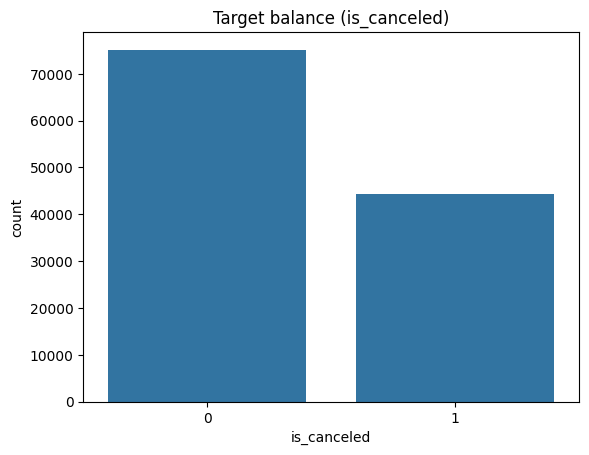

In [4]:
# class balance visual
sns.countplot(x="is_canceled", data=df)
plt.title("Target balance (is_canceled)")
plt.show()

In [5]:
cancel_rate = df['is_canceled'].mean() * 100
print(f"Cancellation rate: {cancel_rate:.2f}%")

Cancellation rate: 37.04%


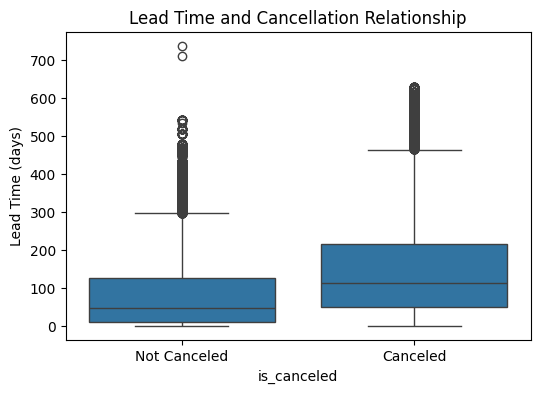

In [6]:
plt.figure(figsize=(6,4))
sns.boxplot(x='is_canceled', y='lead_time', data=df)
plt.title('Lead Time and Cancellation Relationship')
plt.xticks([0,1], ['Not Canceled', 'Canceled'])
plt.ylabel('Lead Time (days)')
plt.show()

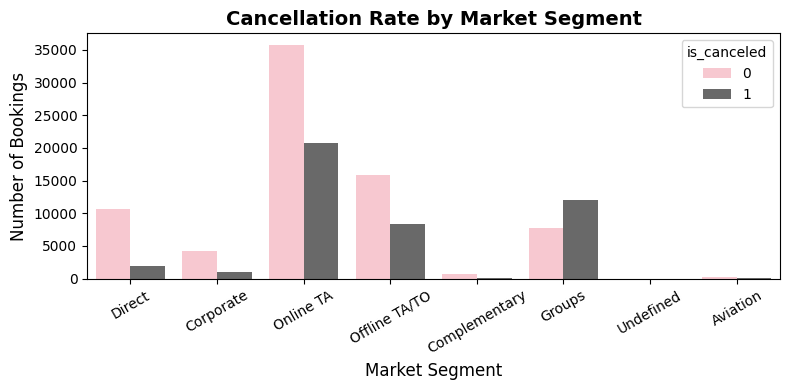

In [7]:
plt.figure(figsize=(8,4))
sns.countplot(
    x='market_segment',
    hue='is_canceled',
    data=df,
    palette=['pink', 'dimgray']  # pink for canceled, grey for not canceled
)
plt.title('Cancellation Rate by Market Segment', fontsize=14, fontweight='bold', color='black')
plt.xlabel('Market Segment', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

C:\Users\azerty\AppData\Local\Temp\ipykernel_4332\2883008888.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\azerty\AppData\Local\Temp\ipykernel_4332\2883008888.py:2: UserWarning: 
The palette list has fewer values (2) than needed (6) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


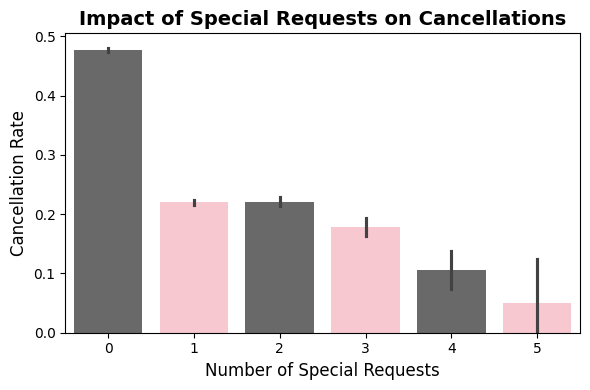

In [8]:
plt.figure(figsize=(6,4))
sns.barplot(
    x='total_of_special_requests',
    y='is_canceled',
    data=df,
    palette=['dimgray', 'pink']  # consistent color scheme
)
plt.title('Impact of Special Requests on Cancellations', fontsize=14, fontweight='bold', color='black')
plt.xlabel('Number of Special Requests', fontsize=12)
plt.ylabel('Cancellation Rate', fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
#  Printing the different values for every feature
print("\n=== Unique values per column ===")
for feature in df.columns:
    print(feature, "->", df[feature].nunique(), "unique values")
    


=== Unique values per column ===
hotel -> 2 unique values
is_canceled -> 2 unique values
lead_time -> 479 unique values
adults -> 14 unique values
meal -> 5 unique values
market_segment -> 8 unique values
is_repeated_guest -> 2 unique values
previous_cancellations -> 15 unique values
booking_changes -> 21 unique values
deposit_type -> 3 unique values
customer_type -> 4 unique values
adr -> 8879 unique values
total_of_special_requests -> 6 unique values


In [10]:
# ------------------------------------------------------------------
# Data preparation (following original example steps)
# Convert categorical columns using LabelEncoder
df = pd.get_dummies(df,

                    columns=['hotel', 'meal', 'market_segment', 'customer_type', 'deposit_type'],

                    drop_first=True)
df.shape
df.head()

,is_canceled,lead_time,adults,is_repeated_guest,previous_cancellations,booking_changes,adr,total_of_special_requests,hotel_Resort Hotel,meal_FB,...,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,deposit_type_Non Refund,deposit_type_Refundable
0,0,342,2,0,0,3,0.0,0,True,False,...,True,False,False,False,False,False,True,False,False,False
1,0,737,2,0,0,4,0.0,0,True,False,...,True,False,False,False,False,False,True,False,False,False
2,0,7,1,0,0,0,75.0,0,True,False,...,True,False,False,False,False,False,True,False,False,False
3,0,13,1,0,0,0,75.0,0,True,False,...,False,False,False,False,False,False,True,False,False,False
4,0,14,2,0,0,0,98.0,1,True,False,...,False,False,False,True,False,False,True,False,False,False


In [11]:
# 4. SPLITTING DATA INTO FEATURES & TARGET

# ================================================================
target_col = "is_canceled"
y = df[target_col]
X = df.drop(columns=[target_col])

 

In [12]:
# Low variance filter
vt = VarianceThreshold(threshold=0.01)
vt.fit(X)
X = X.loc[:, vt.get_support()]

In [13]:
# 14. Settings 
k_anova = 15     # top-k for ANOVA (continuous)
k_chi2  = 15     # top-k for Chi-square (categorical 0/1)
k_rfe   = 15     # number of features RFE should keep


In [14]:
# Separate categorical and continuous features
uniq = X.nunique(dropna=False)
cat_cols = uniq[uniq == 2].index.tolist()
con_cols = uniq[uniq > 2].index.tolist()
df1 = X[cat_cols]
df2 = X[con_cols]

print("Categorical (df1):", df1.columns.tolist())
print("Continuous (df2):", df2.columns.tolist())

 

Categorical (df1): ['is_repeated_guest', 'hotel_Resort Hotel', 'meal_HB', 'meal_SC', 'market_segment_Corporate', 'market_segment_Direct', 'market_segment_Groups', 'market_segment_Offline TA/TO', 'market_segment_Online TA', 'customer_type_Transient', 'customer_type_Transient-Party', 'deposit_type_Non Refund']
Continuous (df2): ['lead_time', 'adults', 'previous_cancellations', 'booking_changes', 'adr', 'total_of_special_requests']


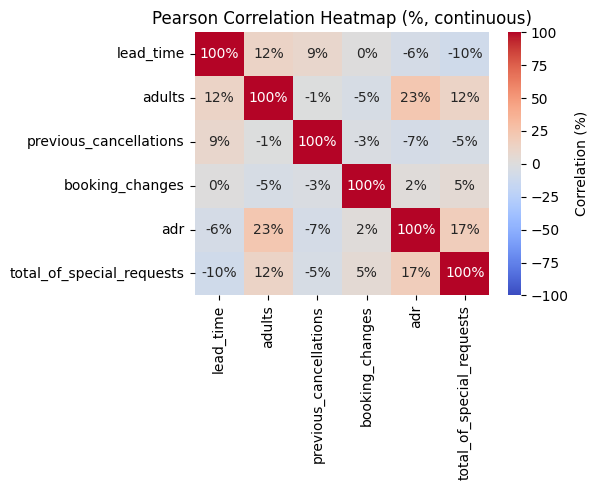

In [15]:
# Pearson heatmap
if df2.shape[1] >= 2:

    corr_pct = df2.corr(numeric_only=True, method='pearson') * 100.0

    annot_labels = corr_pct.round(0).astype(int).astype(str) + "%"

    plt.figure(figsize=(max(6, 0.5*len(corr_pct.columns)), max(5, 0.5*len(corr_pct.columns))))

    ax = sns.heatmap(corr_pct, annot=annot_labels, fmt="", vmin=-100, vmax=100,

                     cmap="coolwarm", cbar_kws={"label": "Correlation (%)"})

    ax.set_title("Pearson Correlation Heatmap (%, continuous)")

    plt.tight_layout()

    plt.show()

In [16]:
# ANOVA & Chi2

anova_all = SelectKBest(score_func=f_classif, k='all').fit(df2, y) if df2.shape[1] > 0 else None
chi2_all  = SelectKBest(score_func=chi2,     k='all').fit(df1, y) if df1.shape[1] > 0 else None

anova_scores = pd.DataFrame({"feature": df2.columns, "anova_score": anova_all.scores_}) if anova_all is not None else pd.DataFrame(columns=["feature","anova_score"])
chi2_scores  = pd.DataFrame({"feature": df1.columns, "chi2_score":  chi2_all.scores_})   if chi2_all  is not None else pd.DataFrame(columns=["feature","chi2_score"])

anova_scores = anova_scores.fillna(0.0).sort_values("anova_score", ascending=False)
chi2_scores  = chi2_scores.fillna(0.0).sort_values("chi2_score",   ascending=False)

print("\n=== ANOVA scores (continuous) ===")
print(anova_scores)

print("\n=== Chi-square scores (categorical) ===")
print(chi2_scores)


=== ANOVA scores (continuous) ===
                     feature   anova_score
0                  lead_time  11222.198248
5  total_of_special_requests   6957.100859
3            booking_changes   2541.731401
2     previous_cancellations   1465.864983
1                     adults    431.598081
4                        adr    270.623533

=== Chi-square scores (categorical) ===
                          feature    chi2_score
11        deposit_type_Non Refund  24293.423036
6           market_segment_Groups   4901.438975
5           market_segment_Direct   2545.319532
1              hotel_Resort Hotel   1478.773676
10  customer_type_Transient-Party   1452.584353
0               is_repeated_guest    831.011392
4        market_segment_Corporate    760.948889
9         customer_type_Transient    527.389741
7    market_segment_Offline TA/TO     77.149911
2                         meal_HB     41.322393
8        market_segment_Online TA      2.487390
3                         meal_SC      0.178688

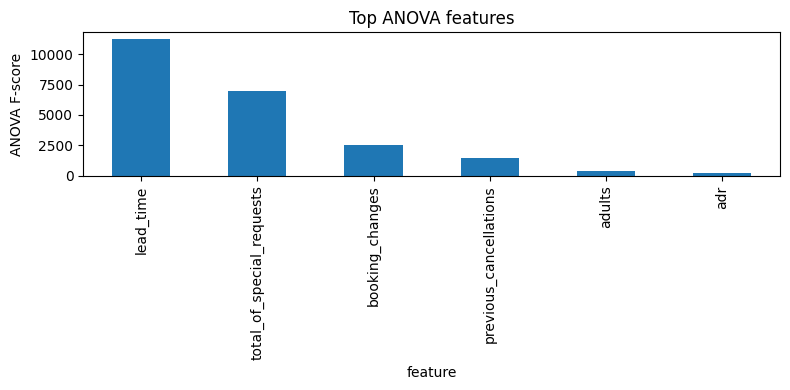

Interpretation (ANOVA): Higher F-scores = stronger mean-difference across loan_status groups; near-zero ≈ weak signal in continuous features.


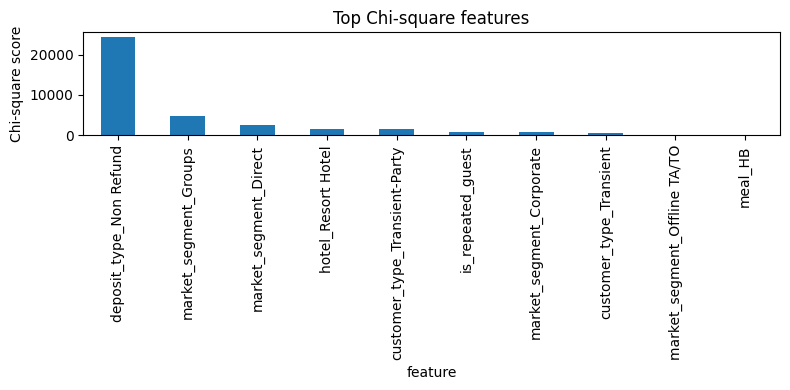

Interpretation (Chi-square): Higher χ² = stronger dependence between 0/1 feature and loan_status; ~0 suggests little association.


In [17]:
# Bar plots
if anova_scores.shape[0] > 0:
    top_anova_plot = anova_scores.head(10).set_index("feature")["anova_score"]
    plt.figure(figsize=(8, 4))
    top_anova_plot.plot(kind="bar")
    plt.ylabel("ANOVA F-score")
    plt.title("Top ANOVA features")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
    print("Interpretation (ANOVA): Higher F-scores = stronger mean-difference across loan_status groups; near-zero ≈ weak signal in continuous features.")


if chi2_scores.shape[0] > 0:
    top_chi2_plot = chi2_scores.head(10).set_index("feature")["chi2_score"]
    plt.figure(figsize=(8, 4))
    top_chi2_plot.plot(kind="bar")
    plt.ylabel("Chi-square score")
    plt.title("Top Chi-square features")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
    print("Interpretation (Chi-square): Higher χ² = stronger dependence between 0/1 feature and loan_status; ~0 suggests little association.")


=== RFE ranks (1 = best) & scores ===
                          feature  rfe_rank  rfe_score
1                          adults         1   1.000000
2               is_repeated_guest         1   1.000000
3          previous_cancellations         1   1.000000
4                 booking_changes         1   1.000000
7              hotel_Resort Hotel         1   1.000000
6       total_of_special_requests         1   1.000000
9                         meal_SC         1   1.000000
8                         meal_HB         1   1.000000
13   market_segment_Offline TA/TO         1   1.000000
14       market_segment_Online TA         1   1.000000
10       market_segment_Corporate         1   1.000000
11          market_segment_Direct         1   1.000000
15        customer_type_Transient         1   1.000000
16  customer_type_Transient-Party         1   1.000000
17        deposit_type_Non Refund         1   1.000000
0                       lead_time         2   0.500000
5                         

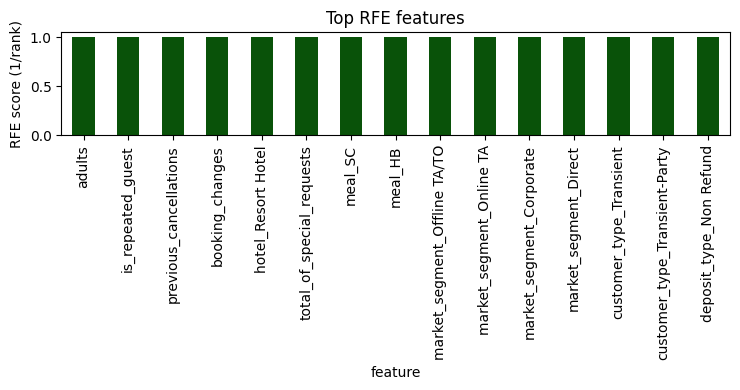

Interpretation (RFE): Rank=1 are strongest per the wrapper; higher 1/rank bars indicate features the model relied on more during recursive elimination.


In [18]:
# ===Wrapper: RFE (Logistic Regression) =====
n_rfe = k_rfe if X.shape[1] >= k_rfe else max(1, X.shape[1])
rfe_est = LogisticRegression(max_iter=1000, solver='liblinear')
rfe = RFE(estimator=rfe_est, n_features_to_select=n_rfe, step=1)
rfe.fit(X, y)

rfe_tbl = pd.DataFrame({"feature": X.columns, "rfe_rank": rfe.ranking_})
rfe_tbl["rfe_score"] = 1.0 / rfe_tbl["rfe_rank"]
rfe_tbl = rfe_tbl.sort_values("rfe_rank", ascending=True)

print("\n=== RFE ranks (1 = best) & scores ===")
print(rfe_tbl)

top_rfe_plot = rfe_tbl.head(min(k_rfe, rfe_tbl.shape[0])).set_index("feature")["rfe_score"]
plt.figure(figsize=(max(6, 0.5*len(top_rfe_plot.index)), 4))
top_rfe_plot.plot(kind="bar",color="#095209")
plt.ylabel("RFE score (1/rank)")
plt.title("Top RFE features")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
print("Interpretation (RFE): Rank=1 are strongest per the wrapper; higher 1/rank bars indicate features the model relied on more during recursive elimination.")

In [19]:
# ===== Select different top-k per method, then UNION for modeling =====
selected_anova = anova_scores["feature"].head(k_anova).tolist()
selected_chi2  = chi2_scores["feature"].head(k_chi2).tolist()
selected_rfe   = rfe_tbl["feature"].head(k_rfe).tolist()

selected_union = list(set(selected_anova) | set(selected_chi2) | set(selected_rfe))
X_final = X[selected_union] if len(selected_union) > 0 else X

print("\nTop by ANOVA:", selected_anova)
print("Top by Chi-square:", selected_chi2)
print("Top by RFE:", selected_rfe)
print("\n=== Final feature set (union) ===")
print(selected_union)
X_final.shape


Top by ANOVA: ['lead_time', 'total_of_special_requests', 'booking_changes', 'previous_cancellations', 'adults', 'adr']
Top by Chi-square: ['deposit_type_Non Refund', 'market_segment_Groups', 'market_segment_Direct', 'hotel_Resort Hotel', 'customer_type_Transient-Party', 'is_repeated_guest', 'market_segment_Corporate', 'customer_type_Transient', 'market_segment_Offline TA/TO', 'meal_HB', 'market_segment_Online TA', 'meal_SC']
Top by RFE: ['adults', 'is_repeated_guest', 'previous_cancellations', 'booking_changes', 'hotel_Resort Hotel', 'total_of_special_requests', 'meal_SC', 'meal_HB', 'market_segment_Offline TA/TO', 'market_segment_Online TA', 'market_segment_Corporate', 'market_segment_Direct', 'customer_type_Transient', 'customer_type_Transient-Party', 'deposit_type_Non Refund']

=== Final feature set (union) ===
['adults', 'market_segment_Groups', 'is_repeated_guest', 'previous_cancellations', 'total_of_special_requests', 'hotel_Resort Hotel', 'market_segment_Corporate', 'customer_t

(119390, 18)

In [20]:
# ==== UPDATED IMPORTS ====
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, confusion_matrix)
from sklearn.neural_network import MLPClassifier   
# ------------------------------------------------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  


In [21]:
# # Classifiers 
models = {
    'LinearSVM'        :LinearSVC(max_iter=10000,          
                              random_state=42),
    'Decision Tree'     : DecisionTreeClassifier(random_state=42),
    'Random Forest'     : RandomForestClassifier(random_state=42),
    'Naive Bayes'       : GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42),
    'Gradient Boosting' : GradientBoostingClassifier(random_state=42),
    # -------------------  ANN ENTRY ----------------------------
    'ANN': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        batch_size=128,              
        learning_rate_init=1e-3,
        max_iter=300,              
        early_stopping=True,        
        n_iter_no_change=10,        
        random_state=42,
        verbose=False)
}

In [22]:
# ==== Per-model grids ====
param_grids = {
    'LinearSVM': {
    'C': [0.1, 1, 10],  
    'loss': ['squared_hinge', 'hinge']  
},
    'Decision Tree': {
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    'Random Forest': {
        'n_estimators': [100],
        'max_depth': [None, 10],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2]
    },
    'Naive Bayes': {
        'var_smoothing': np.logspace(-10, -7, 4)
    },
    'Logistic Regression': {
        'C': [0.1, 1, 10],
        'penalty': ['l2'],             
        'solver': ['lbfgs'],           
        'class_weight': [None, 'balanced']
    },
    'Gradient Boosting': {
        'n_estimators': [100],
        'learning_rate': [ 0.1],
        'max_depth': [ 3]
    },
    'ANN': {
        'hidden_layer_sizes': [(64,32)],
        'alpha': [1e-4],
        'batch_size': [128],
        'learning_rate_init': [1e-3]
    }
}

In [38]:
# ------------------------------------------------------------------
# Main evaluation loop
for model_name, model in models.items():
    acc, prec, rec, f1 = [], [], [], []
    cm_sum = None 

    # track best params per fold to print a representative set later
    fold_best_params = []
    fold_f1_scores   = []

    for train_idx, test_idx in skf.split(X_final, y):
        # split
        X_train, X_test = X_final.iloc[train_idx], X_final.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # scale  (your original scaling kept)
        scaler = MinMaxScaler().fit(X_train)
        X_train = scaler.transform(X_train)
        X_test  = scaler.transform(X_test)

        #per-fold grid search around the current model ====
        grid = GridSearchCV(
            estimator=model,
            param_grid=param_grids[model_name],
            scoring='f1',             # binary F1; adjust if needed
            cv=2,                     # inner CV
            n_jobs=-1,
            refit=True
        )
        grid.fit(X_train, y_train)
        best_model = grid.best_estimator_
        fold_best_params.append(grid.best_params_)

        # predict with best model for this fold
        y_pred = best_model.predict(X_test)

        # metrics for this fold
        acc_i = accuracy_score(y_test, y_pred)
        prec_i = precision_score(y_test, y_pred)
        rec_i = recall_score(y_test, y_pred)
        f1_i = f1_score(y_test, y_pred)

        acc.append(acc_i); prec.append(prec_i); rec.append(rec_i); f1.append(f1_i)
        fold_f1_scores.append(f1_i)

        cm_fold = confusion_matrix(y_test, y_pred, labels=np.unique(y))
        cm_sum = cm_fold if cm_sum is None else cm_sum + cm_fold
# ------------------------------------------------------------------
    # choose the hyperparameters from the fold that achieved the highest F1
    best_fold_idx = int(np.argmax(fold_f1_scores))
    representative_best_params = fold_best_params[best_fold_idx]

    print(f"\n{model_name}")
    print(f"  Best params (best fold): {representative_best_params}")
    print(f"  Accuracy : {np.mean(acc):.4f} ± {np.std(acc):.4f}")
    print(f"  Precision: {np.mean(prec):.4f}")
    print(f"  Recall   : {np.mean(rec):.4f}")
    print(f"  F1-score : {np.mean(f1):.4f}")
    print("  Confusion matrix (total over 5 folds):" )
    print(cm_sum)



LinearSVM
  Best params (best fold): {'C': 10, 'loss': 'squared_hinge'}
  Accuracy : 0.7939 ± 0.0016
  Precision: 0.8726
  Recall   : 0.5196
  F1-score : 0.6513
  Confusion matrix (total over 5 folds):
[[71809  3357]
 [21245 22979]]

Decision Tree
  Best params (best fold): {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
  Accuracy : 0.8035 ± 0.0011
  Precision: 0.8148
  Recall   : 0.6078
  F1-score : 0.6962
  Confusion matrix (total over 5 folds):
[[69054  6112]
 [17345 26879]]

Random Forest
  Best params (best fold): {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
  Accuracy : 0.8138 ± 0.0014
  Precision: 0.8562
  Recall   : 0.5977
  F1-score : 0.7039
  Confusion matrix (total over 5 folds):
[[70725  4441]
 [17791 26433]]

Naive Bayes
  Best params (best fold): {'var_smoothing': np.float64(1e-10)}
  Accuracy : 0.7603 ± 0.0012
  Precision: 0.9456
  Recall   : 0.3744
  F1-score : 0.5364
  Confusion matrix (total over 5 folds):
[[7